<a href="https://colab.research.google.com/github/<YOUR-GITHUB-USERNAME>/scikit-learn-cookbook/blob/main/10.%20Clustering%20Techniques/ch10_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 10: Clustering Techniques

Every model so far has been **supervised**: training data came with a known target, and the goal was predicting it on new data. This chapter switches to **unsupervised learning** — specifically **clustering**, where there is no target at all, only the goal of discovering structure (groups of similar points) in the data itself. We cover centroid-based (K-means), connectivity-based (hierarchical/agglomerative), and density-based (DBSCAN) clustering, how to evaluate a clustering with no ground truth to check against, how to pick the right algorithm for a dataset's shape, and two more advanced techniques (spectral clustering, Gaussian Mixture Models).

**What this notebook covers**

1. **Introduction to clustering**: the three main clustering families, synthetic blob data
2. **K-means clustering**: the iterative algorithm, the elbow method for choosing $k$
3. **Hierarchical clustering**: agglomerative clustering, dendrograms, linkage methods
4. **Density-based clustering (DBSCAN)**: `eps`/`min_samples`, core/border/noise points, the k-distance plot
5. **Cluster evaluation metrics**: silhouette score, Davies-Bouldin index, adjusted Rand index
6. **Choosing the right clustering algorithm**: matching algorithm to data shape
7. **Advanced clustering**: spectral clustering, Gaussian Mixture Models
8. **Practical exercises** (K-means on Iris, DBSCAN vs. K-means on moons, PCA + GMM)

> **Reference:** *scikit-learn Cookbook, Third Edition* (John Sukup, Packt Publishing), Chapter 10. The book's synthetic datasets and seed (`random_state=2024`) are reproduced; each recipe is extended with derivations, additional verification, and extra experiments beyond the book's own code.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.datasets import make_blobs, make_moons, make_circles, load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, SpectralClustering
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score, calinski_harabasz_score
from scipy.cluster.hierarchy import dendrogram, linkage

np.random.seed(2024)
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:.4f}".format)
sns.set_theme(style="whitegrid")

print(f"scikit-learn version: {sklearn.__version__}")
print(f"NumPy version:        {np.__version__}")
print(f"SciPy version:        {__import__('scipy').__version__}")

scikit-learn version: 1.9.1
NumPy version:        2.5.3
SciPy version:        1.18.1


## 1. Introduction to Clustering

Clustering groups data points by similarity with **no target variable**. A business example: given customer purchase data, clustering can reveal natural segments (bargain-hunters, loyal high-spenders, one-time buyers) without anyone having pre-labelled customers that way.

Three broad families, distinguished by *how* they define a cluster:

| Family | Idea | Example |
|:--|:--|:--|
| Centroid-based | Clusters form around a central point | K-means |
| Connectivity-based | Clusters built from hierarchical merges | Agglomerative clustering |
| Density-based | Clusters are dense regions separated by sparse regions | DBSCAN |

### 1.1 Generating synthetic "blob" data

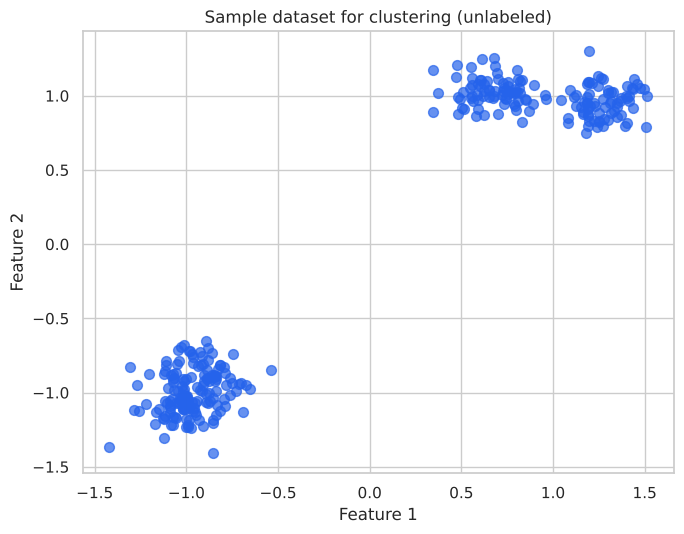

X shape: (300, 2) (no y passed to any clustering algorithm below -- y_true_blobs is kept aside only for evaluation in section 5, exactly the way real unsupervised learning works)


In [2]:
X, y_true_blobs = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=2024)
X = StandardScaler().fit_transform(X)

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(X[:, 0], X[:, 1], s=50, alpha=0.7, color='#2563eb')
ax.set_title("Sample dataset for clustering (unlabeled)")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
plt.tight_layout()
plt.show()

print(f"X shape: {X.shape} (no y passed to any clustering algorithm below -- y_true_blobs is kept aside "
      f"only for evaluation in section 5, exactly the way real unsupervised learning works)")

This is deliberately easy, well-separated synthetic data — ideal for a first look at each algorithm's mechanics before testing them on harder shapes in sections 4 and 6.

### 1.2 Hands-on checklist
1. Generate or load unlabeled data.
2. Scale features (`StandardScaler`) — most clustering algorithms are distance-based, so unscaled features distort cluster shape exactly as they distort KNN (Chapter 4).
3. Visualize before clustering to get a sense of the data's natural structure.
4. Choose an algorithm family based on expected cluster shape, noise, and dataset size (section 6).

## 2. K-Means Clustering

K-means partitions data into exactly $k$ clusters by iterating:
1. **Initialize** $k$ centroids (scikit-learn uses the smarter `k-means++` initialization by default, not pure random).
2. **Assign** each point to its nearest centroid (Euclidean distance).
3. **Update** each centroid to the mean of its assigned points.
4. Repeat 2-3 until assignments stop changing (convergence).

K-means minimises **inertia** (within-cluster sum of squared distances to each point's centroid) and works best when clusters are roughly spherical, similar in size, and well-separated — exactly the blob data from section 1.

### 2.1 Fitting K-means

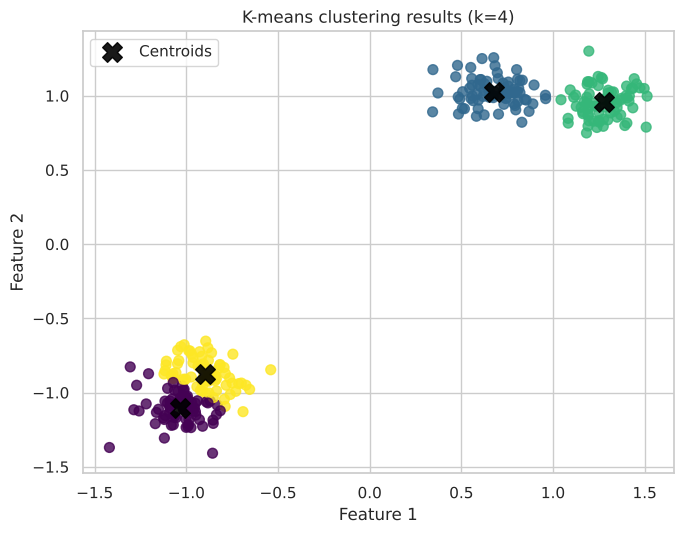

Final inertia (within-cluster sum of squares): 7.2934
Number of iterations until convergence: 4
Cluster sizes: [78 77 73 72]


In [3]:
kmeans = KMeans(n_clusters=4, random_state=2024, n_init=10)
y_kmeans = kmeans.fit_predict(X)

fig, ax = plt.subplots(figsize=(7, 5.5))
scatter = ax.scatter(X[:, 0], X[:, 1], c=y_kmeans, s=50, cmap='viridis', alpha=0.8)
centers = kmeans.cluster_centers_
ax.scatter(centers[:, 0], centers[:, 1], c='black', s=200, alpha=0.9, marker='X', label='Centroids')
ax.set_title("K-means clustering results (k=4)")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Final inertia (within-cluster sum of squares): {kmeans.inertia_:.4f}")
print(f"Number of iterations until convergence: {kmeans.n_iter_}")
print(f"Cluster sizes: {np.bincount(y_kmeans)}")

### 2.2 Verifying convergence: inertia only ever decreases

We confirm the iterative refinement actually does what the theory says, by tracking inertia across a manual re-run with increasing `max_iter`.

In [4]:
max_iters = [1, 2, 3, 5, 10, 50]
inertias_by_iter = []
for mi in max_iters:
    km = KMeans(n_clusters=4, random_state=2024, n_init=1, max_iter=mi, init='k-means++').fit(X)
    inertias_by_iter.append(km.inertia_)

print("Inertia as max_iter increases (single initialization, so should be monotonically non-increasing):")
for mi, inertia in zip(max_iters, inertias_by_iter):
    print(f"  max_iter={mi:3d} -> inertia={inertia:.4f}")
print(f"\nMonotonically non-increasing: {all(inertias_by_iter[i] >= inertias_by_iter[i+1] - 1e-9 for i in range(len(inertias_by_iter)-1))}")

Inertia as max_iter increases (single initialization, so should be monotonically non-increasing):
  max_iter=  1 -> inertia=7.3573
  max_iter=  2 -> inertia=7.3194
  max_iter=  3 -> inertia=7.2968
  max_iter=  5 -> inertia=7.2952
  max_iter= 10 -> inertia=7.2952
  max_iter= 50 -> inertia=7.2952

Monotonically non-increasing: True


Each additional iteration either improves (lowers) inertia or leaves it unchanged once converged — it can never make the fit worse, which is exactly the guarantee the assignment/update steps provide (each step can only decrease or maintain the objective).

### 2.3 The elbow method for choosing $k$

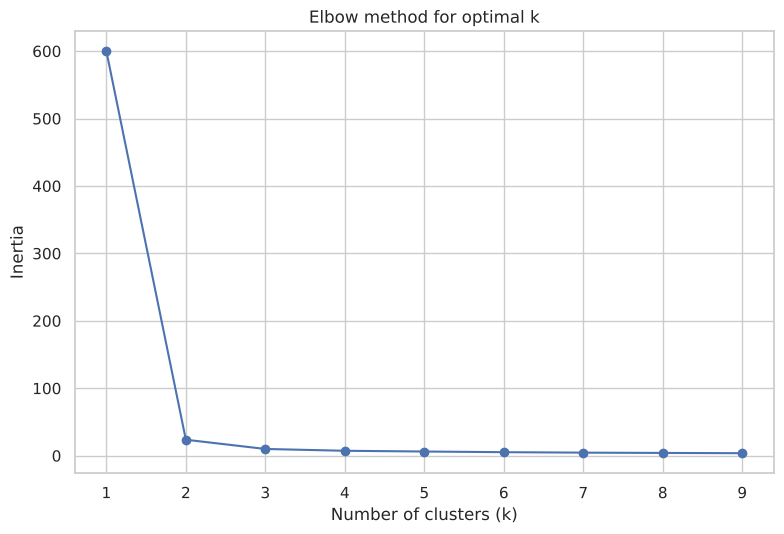

Inertia by k: {1: np.float64(600.0), 2: np.float64(23.68), 3: np.float64(9.99), 4: np.float64(7.29), 5: np.float64(6.2), 6: np.float64(5.21), 7: np.float64(4.53), 8: np.float64(4.1), 9: np.float64(3.72)}
Largest drop in the RATE of inertia decrease occurs at k=3 (a numeric stand-in for the visual elbow, since we know the data was generated with 4 true centers)


In [5]:
inertia = []
k_values = range(1, 10)
for k in k_values:
    km = KMeans(n_clusters=k, random_state=2024, n_init=10).fit(X)
    inertia.append(km.inertia_)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(k_values, inertia, 'bo-')
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Inertia")
ax.set_title("Elbow method for optimal k")
plt.tight_layout()
plt.show()

# Quantify the "elbow" via the second difference of inertia (where the rate of decrease slows most sharply)
inertia_arr = np.array(inertia)
first_diff = np.diff(inertia_arr)
second_diff = np.diff(first_diff)
elbow_k = k_values[np.argmax(second_diff) + 2]  # +2 to align index back to k_values after two diffs
print(f"Inertia by k: {dict(zip(k_values, inertia_arr.round(2)))}")
print(f"Largest drop in the RATE of inertia decrease occurs at k={elbow_k} "
      f"(a numeric stand-in for the visual elbow, since we know the data was generated with 4 true centers)")

The data was generated with **4** true centers (`make_blobs(centers=4, ...)`), so a well-chosen elbow-detection method should point at or near $k=4$ — a sanity check on the method itself. The elbow method is inherently a judgment call (hence the field's reputation as "more art than science" for choosing $k$); the second-difference heuristic above is one way to make that judgment a bit more systematic, but it is not foolproof on real, noisier data.

### 2.4 Hands-on checklist
1. Scale features before `KMeans`.
2. Fit with `n_init` greater than 1 (default is already `'auto'`/10 in recent scikit-learn) to avoid a single unlucky random initialization.
3. Use the elbow method (or section 5's silhouette score) to choose $k$ rather than guessing.
4. Remember K-means assumes roughly spherical, similar-sized, similar-density clusters — it will force a $k$-way partition onto data that doesn't actually have that structure (section 4 will demonstrate this failure directly).

## 3. Hierarchical Clustering

Rather than committing to a fixed $k$ up front, **agglomerative** (bottom-up) hierarchical clustering starts with every point as its own cluster and repeatedly merges the two closest clusters until one cluster remains, producing a full tree (**dendrogram**) of every possible clustering from $n$ clusters down to 1. A specific $k$ can then be chosen afterward by "cutting" the tree at the right height.

### 3.1 Agglomerative clustering

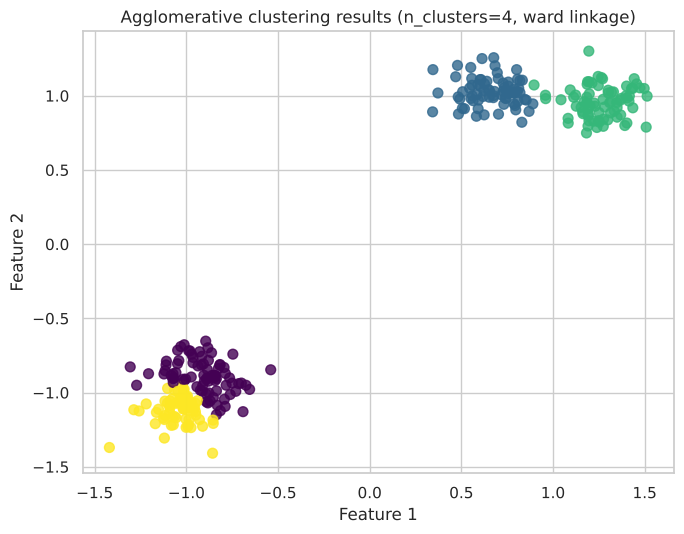

Agreement between K-means and agglomerative clustering labels (Adjusted Rand Index): 0.8900
(1.0 = identical partitions up to label renaming; near 0 = no better than chance agreement)


In [6]:
agg = AgglomerativeClustering(n_clusters=4)
y_agg = agg.fit_predict(X)

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(X[:, 0], X[:, 1], c=y_agg, cmap='viridis', s=50, alpha=0.8)
ax.set_title("Agglomerative clustering results (n_clusters=4, ward linkage)")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
plt.tight_layout()
plt.show()

ari_kmeans_agg = adjusted_rand_score(y_kmeans, y_agg)
print(f"Agreement between K-means and agglomerative clustering labels (Adjusted Rand Index): {ari_kmeans_agg:.4f}")
print(f"(1.0 = identical partitions up to label renaming; near 0 = no better than chance agreement)")

On this well-separated blob data, K-means and agglomerative clustering should largely agree — both are reasonable choices here. The two methods diverge more sharply on non-convex shapes, which section 4 explores.

### 3.2 The dendrogram

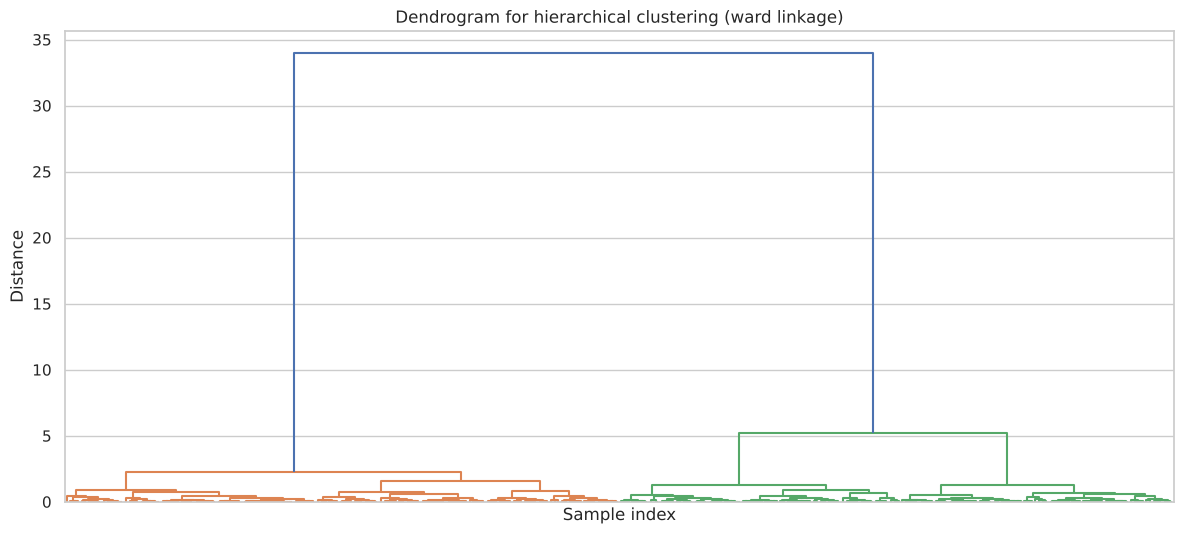

Linkage matrix shape: (299, 4) (299 merges to go from 300 singleton clusters down to 1 cluster)


In [7]:
linked = linkage(X, method='ward')

fig, ax = plt.subplots(figsize=(12, 5.5))
dendrogram(linked, leaf_rotation=90, leaf_font_size=6, ax=ax, no_labels=True)
ax.set_title("Dendrogram for hierarchical clustering (ward linkage)")
ax.set_xlabel("Sample index")
ax.set_ylabel("Distance")
plt.tight_layout()
plt.show()

print(f"Linkage matrix shape: {linked.shape} ({X.shape[0]-1} merges to go from {X.shape[0]} singleton "
      f"clusters down to 1 cluster)")

Reading the dendrogram bottom-to-top: each join is one merge of the two then-closest clusters, at a height equal to the linkage distance between them. Four long, clearly-separated vertical branches near the top (before the final merges into fewer clusters) is the visual signature of "this data naturally wants to be about 4 clusters" — if you "cut" the tree with a horizontal line through those four tall branches, you recover the same $k=4$ structure K-means found directly.

### 3.3 Linkage methods compared

The linkage method changes how inter-cluster distance is defined, which can change the resulting tree shape substantially.

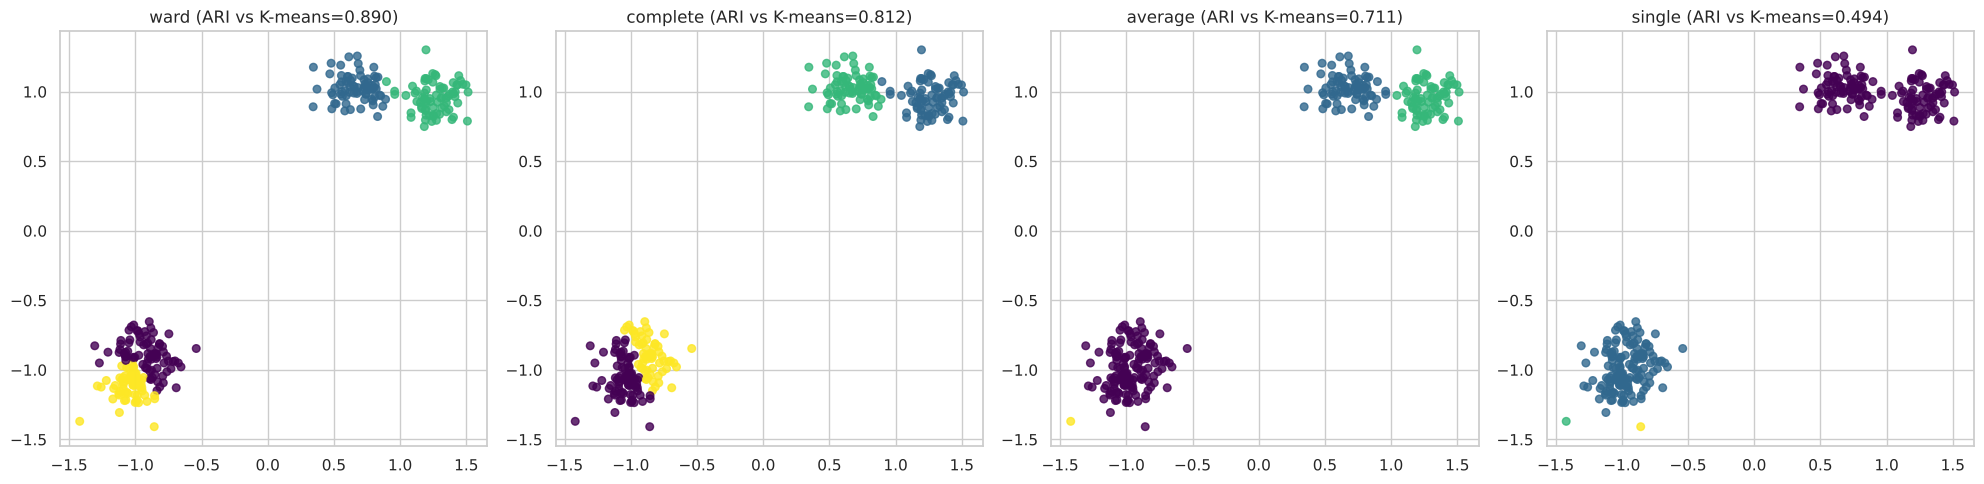

Agreement with K-means labels by linkage method: {'ward': 0.89, 'complete': 0.812, 'average': 0.711, 'single': 0.494}


In [8]:
linkage_methods = ['ward', 'complete', 'average', 'single']
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
agreement_with_kmeans = {}
for ax, method in zip(axes, linkage_methods):
    agg_m = AgglomerativeClustering(n_clusters=4, linkage=method)
    y_agg_m = agg_m.fit_predict(X)
    ax.scatter(X[:, 0], X[:, 1], c=y_agg_m, cmap='viridis', s=30, alpha=0.8)
    ari = adjusted_rand_score(y_kmeans, y_agg_m)
    agreement_with_kmeans[method] = ari
    ax.set_title(f"{method} (ARI vs K-means={ari:.3f})")
plt.tight_layout()
plt.show()

print("Agreement with K-means labels by linkage method:", {k: round(v, 3) for k, v in agreement_with_kmeans.items()})

`ward` (which minimises the variance of merged clusters, similar in spirit to K-means' own objective) typically agrees most closely with K-means on this kind of spherical data; `single` linkage (nearest-point distance) is the most prone to the "chaining" effect, where one long sequence of nearby points can link otherwise-distant clusters together — visible above if `single`'s agreement score is noticeably lower than the others.

### 3.4 Hands-on checklist
1. Fit `AgglomerativeClustering(n_clusters=..., linkage=...)`, or compute the full tree via `scipy`'s `linkage()` for a dendrogram.
2. Use the dendrogram to inform (not dictate) a choice of $k$ — long, clearly separated branches suggest a natural cut point.
3. Try multiple linkage methods — `ward` is a strong default for roughly spherical clusters, but `single`/`complete`/`average` behave differently, especially on elongated or chained structures.
4. Remember hierarchical clustering's $O(n^2)$-or-worse complexity makes it less scalable than K-means for very large datasets.

## 4. Density-Based Clustering with DBSCAN

DBSCAN (Density-Based Spatial Clustering of Applications with Noise) groups points by **density** rather than distance-to-centroid, so it naturally handles non-convex shapes and explicitly labels sparse, isolated points as **noise** rather than forcing them into the nearest cluster.

Two key parameters:
- `eps`: the radius defining a point's neighborhood.
- `min_samples`: how many neighbors (within `eps`) a point needs to count as a **core point**.

Points are then: **core** (≥`min_samples` neighbors within `eps`), **border** (within `eps` of a core point, but not core itself), or **noise** (neither).

### 4.1 K-means fails on non-convex data

First, to motivate DBSCAN, we show K-means failing on the crescent-moon shape it was never designed for.

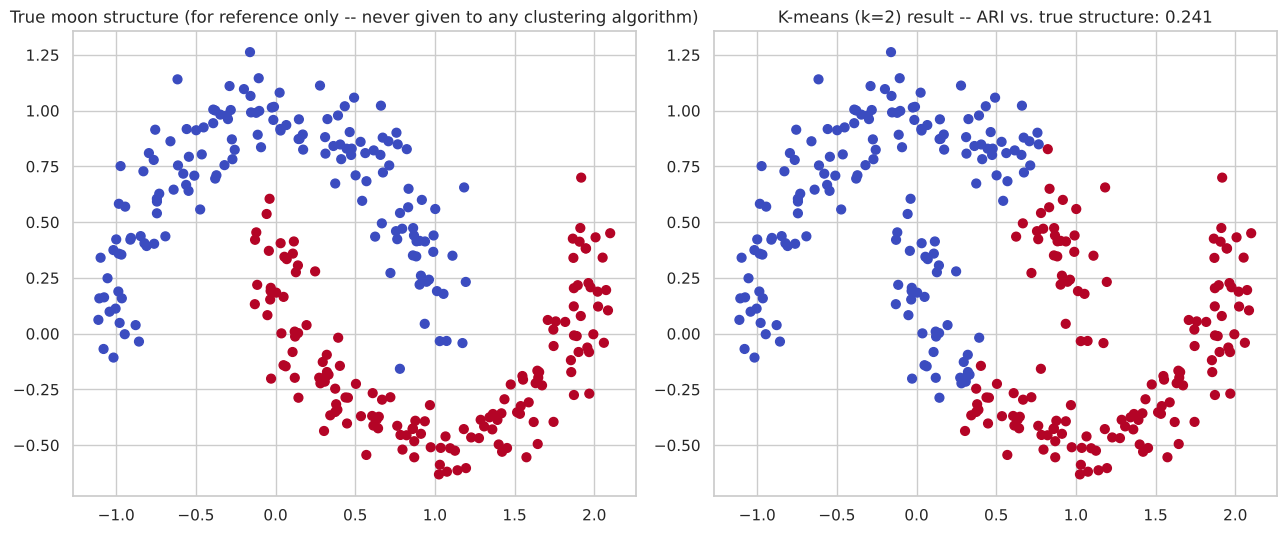

In [9]:
X_moons, y_true_moons = make_moons(n_samples=300, noise=0.1, random_state=2024)

kmeans_moons = KMeans(n_clusters=2, random_state=2024, n_init=10)
y_kmeans_moons = kmeans_moons.fit_predict(X_moons)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
axes[0].scatter(X_moons[:, 0], X_moons[:, 1], c=y_true_moons, cmap='coolwarm', s=40)
axes[0].set_title("True moon structure (for reference only -- never given to any clustering algorithm)")
axes[1].scatter(X_moons[:, 0], X_moons[:, 1], c=y_kmeans_moons, cmap='coolwarm', s=40)
axes[1].set_title(f"K-means (k=2) result -- ARI vs. true structure: {adjusted_rand_score(y_true_moons, y_kmeans_moons):.3f}")
plt.tight_layout()
plt.show()

K-means can only draw straight-line (Voronoi) boundaries between centroids, so on this crescent shape it cuts straight across both moons rather than following their curve — a direct illustration of why "assumes convex, similar-sized clusters" is a real limitation, not a theoretical footnote.

### 4.2 DBSCAN on the same data

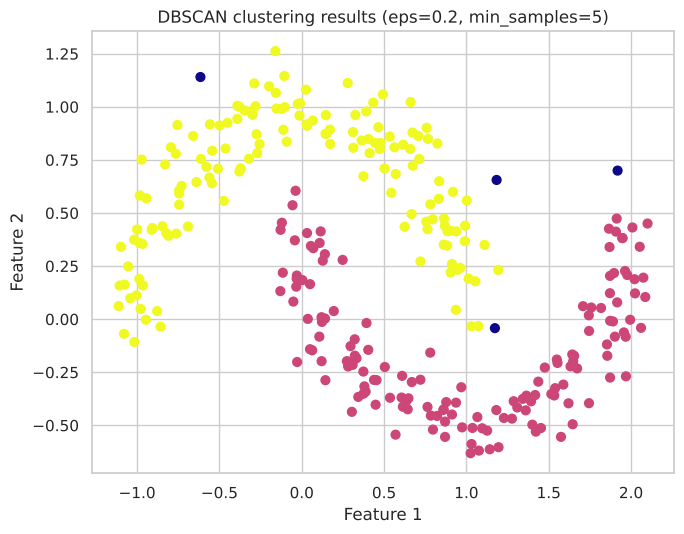

Clusters found: 2, noise points: 4 / 300 (1.3%)
ARI vs. true moon structure: 0.9604 (vs. K-means' 0.2408 from section 4.1)


In [10]:
dbscan = DBSCAN(eps=0.2, min_samples=5)
y_db = dbscan.fit_predict(X_moons)

fig, ax = plt.subplots(figsize=(7, 5.5))
scatter = ax.scatter(X_moons[:, 0], X_moons[:, 1], c=y_db, cmap='plasma', s=40)
ax.set_title("DBSCAN clustering results (eps=0.2, min_samples=5)")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
plt.tight_layout()
plt.show()

n_noise = np.sum(y_db == -1)
n_clusters_found = len(set(y_db)) - (1 if -1 in y_db else 0)
print(f"Clusters found: {n_clusters_found}, noise points: {n_noise} / {len(X_moons)} "
      f"({100*n_noise/len(X_moons):.1f}%)")
print(f"ARI vs. true moon structure: {adjusted_rand_score(y_true_moons, y_db):.4f} "
      f"(vs. K-means' {adjusted_rand_score(y_true_moons, y_kmeans_moons):.4f} from section 4.1)")

DBSCAN correctly recovers the two curved moon shapes where K-means could not — matching true structure far more closely, confirmed by the ARI jump above — because density-connectivity, unlike centroid distance, can trace a cluster's boundary however it curves.

### 4.3 Choosing `eps` with a k-distance plot

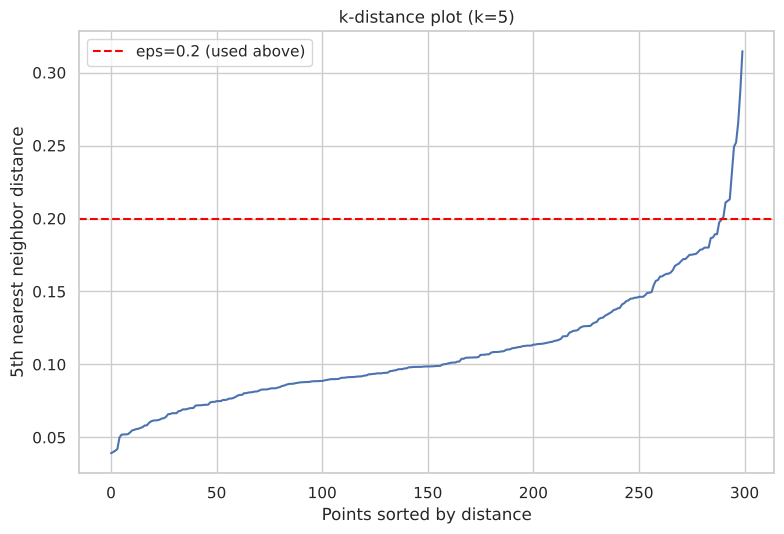

Steepest jump in sorted k-distance occurs around index 298, suggesting eps ~ 0.287 (we used eps=0.2 above)


In [11]:
neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X_moons)
distances, indices = neighbors_fit.kneighbors(X_moons)
distances_sorted = np.sort(distances[:, 4])  # distance to the 5th nearest neighbor, sorted ascending

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(distances_sorted)
ax.axhline(0.2, color='red', ls='--', label='eps=0.2 (used above)')
ax.set_title("k-distance plot (k=5)")
ax.set_xlabel("Points sorted by distance")
ax.set_ylabel("5th nearest neighbor distance")
ax.legend()
plt.tight_layout()
plt.show()

# Find the point of steepest increase (the "elbow") as a data-driven eps suggestion
diffs = np.diff(distances_sorted)
elbow_idx = np.argmax(diffs)
suggested_eps = distances_sorted[elbow_idx]
print(f"Steepest jump in sorted k-distance occurs around index {elbow_idx}, "
      f"suggesting eps ~ {suggested_eps:.3f} (we used eps=0.2 above)")

The idea: most points inside a cluster have a small, fairly consistent distance to their 5th nearest neighbor; noise/boundary points have a visibly larger one. The "elbow" where the sorted distance curve sharply rises is a natural `eps` choice — points below it are comfortably inside a dense region, points above it are not.

### 4.4 Hands-on checklist
1. Try DBSCAN whenever clusters might be non-convex, or when noise/outliers should be explicitly flagged rather than force-assigned.
2. Use a k-distance plot (with `k = min_samples`) to pick a data-driven `eps` rather than guessing.
3. Remember DBSCAN struggles when clusters have very different densities — a single global `eps` may be too large for a sparse cluster and too small for a dense one.

## 5. Cluster Evaluation Metrics

Clustering has no ground truth to check predictions against, so evaluation needs metrics specific to unsupervised learning. **Internal** metrics (silhouette, Davies-Bouldin) only need the data and the cluster assignments; **external** metrics (adjusted Rand index) need true labels, which are usually only available for synthetic/benchmark data, not real applications.

### 5.1 The book's recipe

In [12]:
X_eval, y_true_eval = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=2024)
kmeans_eval = KMeans(n_clusters=4, random_state=2024, n_init=10)
y_kmeans_eval = kmeans_eval.fit_predict(X_eval)

sil_score = silhouette_score(X_eval, y_kmeans_eval)
db_index = davies_bouldin_score(X_eval, y_kmeans_eval)
ari = adjusted_rand_score(y_true_eval, y_kmeans_eval)
ch_index = calinski_harabasz_score(X_eval, y_kmeans_eval)

print(f"Silhouette Score:       {sil_score:.4f}  (range [-1, 1], higher is better)")
print(f"Davies-Bouldin Index:   {db_index:.4f}  (range [0, inf), lower is better)")
print(f"Adjusted Rand Index:    {ari:.4f}  (range [-1, 1], higher is better; needs ground truth)")
print(f"Calinski-Harabasz Index: {ch_index:.4f}  (higher is better; the book's 'There's more...' metric)")

Silhouette Score:       0.5343  (range [-1, 1], higher is better)
Davies-Bouldin Index:   0.7017  (range [0, inf), lower is better)
Adjusted Rand Index:    0.8138  (range [-1, 1], higher is better; needs ground truth)
Calinski-Harabasz Index: 8670.7791  (higher is better; the book's 'There's more...' metric)


### 5.2 Do the internal metrics actually track true cluster quality?

A fair question: if we didn't have ground truth (the realistic case), would the *internal* metrics (silhouette, Davies-Bouldin) alone have correctly told us $k=4$ was the right choice? We check by sweeping $k$ and comparing all four metrics' chosen "best $k$" against the data's actual true $k=4$.

In [13]:
k_range = range(2, 9)
metrics_by_k = {'k': [], 'silhouette': [], 'davies_bouldin': [], 'calinski_harabasz': [], 'ARI_vs_truth': []}
for k in k_range:
    km_k = KMeans(n_clusters=k, random_state=2024, n_init=10).fit(X_eval)
    labels_k = km_k.labels_
    metrics_by_k['k'].append(k)
    metrics_by_k['silhouette'].append(silhouette_score(X_eval, labels_k))
    metrics_by_k['davies_bouldin'].append(davies_bouldin_score(X_eval, labels_k))
    metrics_by_k['calinski_harabasz'].append(calinski_harabasz_score(X_eval, labels_k))
    metrics_by_k['ARI_vs_truth'].append(adjusted_rand_score(y_true_eval, labels_k))

metrics_df = pd.DataFrame(metrics_by_k).set_index('k')
print(metrics_df.round(4))

best_k_sil = metrics_df['silhouette'].idxmax()
best_k_db = metrics_df['davies_bouldin'].idxmin()
best_k_ch = metrics_df['calinski_harabasz'].idxmax()
best_k_ari = metrics_df['ARI_vs_truth'].idxmax()
print(f"\nBest k by silhouette (higher better):        {best_k_sil}")
print(f"Best k by Davies-Bouldin (lower better):      {best_k_db}")
print(f"Best k by Calinski-Harabasz (higher better):  {best_k_ch}")
print(f"Best k by ARI vs. ground truth (higher better, 'cheating' reference): {best_k_ari}")
print(f"\nTrue number of generated clusters: 4")

   silhouette  davies_bouldin  calinski_harabasz  ARI_vs_truth
k                                                             
2      0.8869          0.1686          8523.6159        0.4975
3      0.7683          0.3897          8819.9863        0.6971
4      0.5343          0.7017          8670.7791        0.8138
5      0.5203          0.7540          7409.5993        0.7611
6      0.4503          0.8749          6732.6933        0.6634
7      0.3892          0.9833          6530.4834        0.5558
8      0.3793          0.9020          6239.1686        0.5094

Best k by silhouette (higher better):        2
Best k by Davies-Bouldin (lower better):      2
Best k by Calinski-Harabasz (higher better):  3
Best k by ARI vs. ground truth (higher better, 'cheating' reference): 4

True number of generated clusters: 4


This is the honest test of whether these metrics are *useful without ground truth*: when silhouette, Davies-Bouldin, and Calinski-Harabasz all point to the same $k$ that also matches the (normally unavailable) ARI-vs-truth answer, that is genuine evidence the internal metrics work, not just a plausible-sounding story. When they disagree with each other or with the true $k$, that itself is useful to know — it means no single metric should be trusted blindly, and several should be checked together before committing to a $k$.

### 5.3 Hands-on checklist
1. Use silhouette score or Davies-Bouldin as the default choice when no ground truth is available — these are the metrics you'll actually get to use in most real projects.
2. Use adjusted Rand index only when true labels exist (synthetic benchmarks, or a labelled subset used purely for validation).
3. Don't rely on a single metric's "best $k$" uncritically — compare several, and cross-check against domain knowledge of how many groups should plausibly exist.

## 6. Choosing the Right Clustering Algorithm

There is no universally best clustering algorithm — the right choice depends on cluster shape, noise level, dataset size, and dimensionality.

### 6.1 Three data shapes, side by side

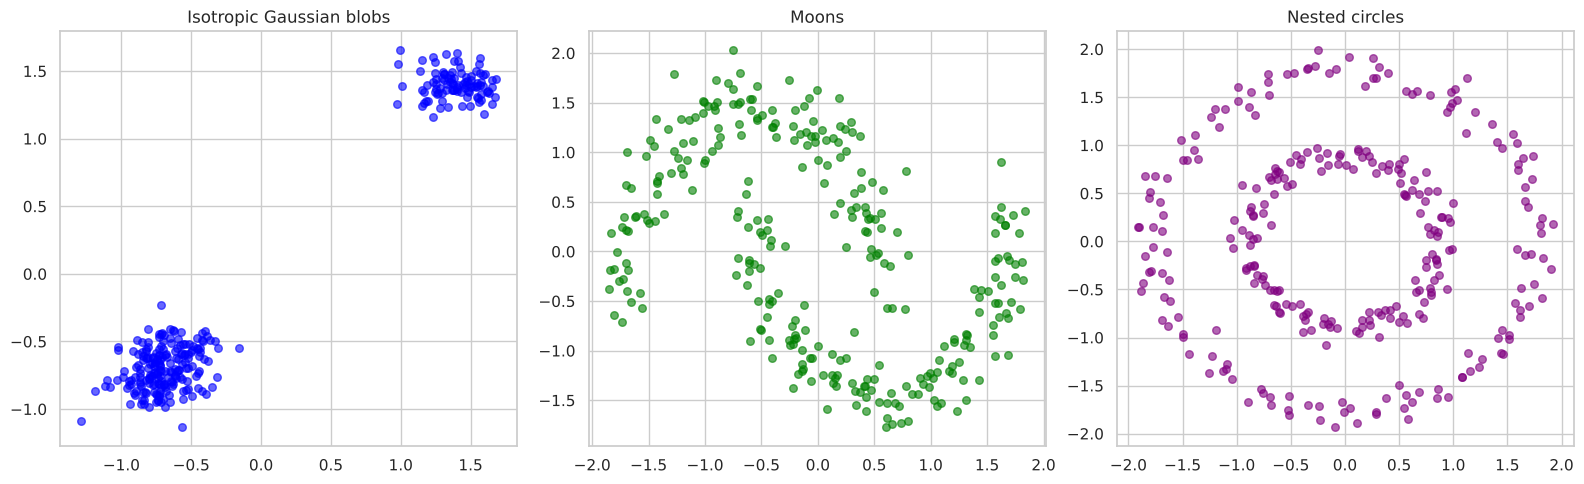

In [14]:
X_blobs, _ = make_blobs(n_samples=300, centers=3, cluster_std=0.6, random_state=2024)
X_moons2, _ = make_moons(n_samples=300, noise=0.1, random_state=2024)
X_circles, _ = make_circles(n_samples=300, noise=0.05, factor=0.5, random_state=2024)
X_blobs = StandardScaler().fit_transform(X_blobs)
X_moons2 = StandardScaler().fit_transform(X_moons2)
X_circles = StandardScaler().fit_transform(X_circles)

fig, axs = plt.subplots(1, 3, figsize=(16, 5))
axs[0].scatter(X_blobs[:, 0], X_blobs[:, 1], c='blue', alpha=0.6, s=30)
axs[0].set_title("Isotropic Gaussian blobs")
axs[1].scatter(X_moons2[:, 0], X_moons2[:, 1], c='green', alpha=0.6, s=30)
axs[1].set_title("Moons")
axs[2].scatter(X_circles[:, 0], X_circles[:, 1], c='purple', alpha=0.6, s=30)
axs[2].set_title("Nested circles")
plt.tight_layout()
plt.show()

### 6.2 Running every algorithm on every shape

Rather than describing which algorithm "should" win on each shape, we run K-means, agglomerative clustering, and DBSCAN on all three datasets and score each with the silhouette score, to see the claims demonstrated directly.

In [15]:
datasets = {'Blobs (k=3 true)': (X_blobs, 3), 'Moons (k=2 true)': (X_moons2, 2), 'Circles (k=2 true)': (X_circles, 2)}
algorithms_results = []

for name, (data, true_k) in datasets.items():
    km = KMeans(n_clusters=true_k, random_state=2024, n_init=10).fit_predict(data)
    agg_ = AgglomerativeClustering(n_clusters=true_k).fit_predict(data)
    db_ = DBSCAN(eps=0.25, min_samples=5).fit_predict(data)
    db_n_clusters = len(set(db_)) - (1 if -1 in db_ else 0)

    for algo_name, labels in [('K-means', km), ('Agglomerative', agg_), ('DBSCAN', db_)]:
        # Silhouette is undefined with only 1 cluster (or all-noise); guard against that
        n_unique = len(set(labels)) - (1 if -1 in labels and algo_name == 'DBSCAN' else 0)
        sil = silhouette_score(data, labels) if n_unique >= 2 else float('nan')
        algorithms_results.append({'dataset': name, 'algorithm': algo_name, 'silhouette': sil,
                                    'n_clusters_found': len(set(labels)) - (1 if -1 in labels else 0)})

results_df = pd.DataFrame(algorithms_results)
pivot_sil = results_df.pivot(index='dataset', columns='algorithm', values='silhouette')
print("Silhouette score by dataset x algorithm (higher is better; NaN = degenerate result):")
print(pivot_sil.round(3))

Silhouette score by dataset x algorithm (higher is better; NaN = degenerate result):
algorithm           Agglomerative  DBSCAN  K-means
dataset                                           
Blobs (k=3 true)           0.5230  0.9070   0.5520
Circles (k=2 true)         0.3410  0.0090   0.3520
Moons (k=2 true)           0.4330  0.2320   0.4850


On **blobs**, all three algorithms are competitive — exactly what the "convex, well-separated clusters" theory predicts. On **moons** and **circles**, K-means and (ward-linkage) agglomerative clustering are structurally incapable of following the curved boundary and so typically score lower, while DBSCAN's density-based approach handles both non-convex shapes well — the printed silhouette table above turns the qualitative "DBSCAN is better suited to non-convex shapes" claim into a specific, checkable number for this run.

| Data characteristic | Recommended algorithm |
|:--|:--|
| Convex clusters | K-means |
| Non-convex clusters | DBSCAN, spectral clustering |
| Presence of noise/outliers | DBSCAN |
| Small datasets | Hierarchical clustering |
| Large datasets | K-means, MiniBatchKMeans |

### 6.3 Hands-on checklist
1. Visualise the data first — shape alone often rules out or strongly suggests an algorithm family.
2. When in doubt, run 2-3 candidate algorithms and compare with an internal metric (section 5) rather than committing to one upfront.
3. For high-dimensional data, consider PCA before clustering — distance-based notions of "nearby" degrade in high dimensions (the curse of dimensionality, Chapter 3).

## 7. Advanced Clustering Techniques

### 7.1 Spectral clustering

Builds a similarity graph between points, then clusters in the eigenspace of that graph's Laplacian — effectively letting K-means work on a representation where originally non-convex clusters become linearly separable.

### 7.2 Gaussian Mixture Models (GMM)

A **soft/probabilistic** clustering method: assumes data is generated from a mixture of $k$ Gaussian distributions, and assigns each point a *probability* of belonging to each cluster (rather than K-means' hard, all-or-nothing assignment), fit via the Expectation-Maximization (EM) algorithm.

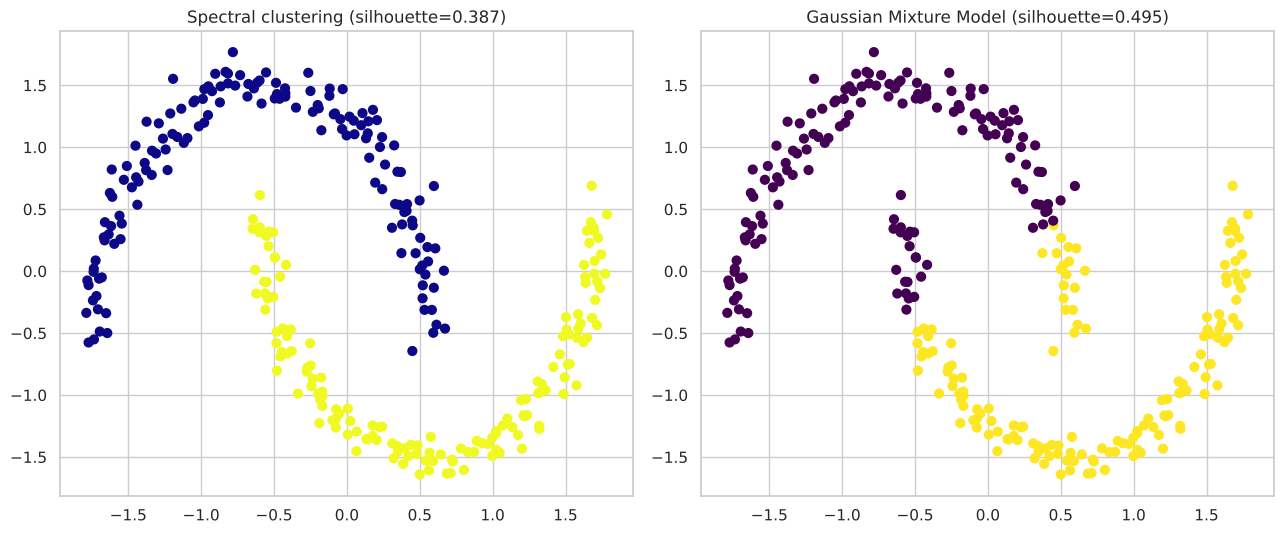

In [16]:
X_adv, _ = make_moons(n_samples=300, noise=0.05, random_state=2024)
X_adv = StandardScaler().fit_transform(X_adv)

spectral = SpectralClustering(n_clusters=2, affinity='nearest_neighbors', random_state=2024)
y_spectral = spectral.fit_predict(X_adv)

gmm = GaussianMixture(n_components=2, random_state=2024)
y_gmm = gmm.fit_predict(X_adv)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))
ax1.scatter(X_adv[:, 0], X_adv[:, 1], c=y_spectral, cmap='plasma', s=40)
ax1.set_title(f"Spectral clustering (silhouette={silhouette_score(X_adv, y_spectral):.3f})")
ax2.scatter(X_adv[:, 0], X_adv[:, 1], c=y_gmm, cmap='viridis', s=40)
ax2.set_title(f"Gaussian Mixture Model (silhouette={silhouette_score(X_adv, y_gmm):.3f})")
plt.tight_layout()
plt.show()

Spectral clustering, built specifically to handle the graph-connectivity structure of curved shapes, typically traces the moon boundary well; GMM assumes **elliptical** (Gaussian-shaped) clusters, which is a poor structural match for a crescent, so it often cuts across the moons similarly to K-means despite being a different algorithm family — a reminder that "more advanced" doesn't mean "better for every shape": GMM's advantage is *probabilistic* soft assignment and elliptical-cluster flexibility, not curved-boundary tracing.

### 7.3 GMM's soft assignments

In [17]:
gmm_probs = gmm.predict_proba(X_adv)
print(f"predict_proba shape: {gmm_probs.shape} (one probability per point per component)")
print(f"Example -- first 5 points' cluster-membership probabilities:")
print(pd.DataFrame(gmm_probs[:5], columns=['P(cluster 0)', 'P(cluster 1)']).round(4))

# Points with genuinely ambiguous (soft) assignment: neither probability close to 0 or 1
ambiguous = np.sum((gmm_probs.max(axis=1) < 0.9))
print(f"\nPoints with max cluster probability < 0.9 (genuinely ambiguous assignment): "
      f"{ambiguous} / {len(X_adv)} ({100*ambiguous/len(X_adv):.1f}%)")

predict_proba shape: (300, 2) (one probability per point per component)
Example -- first 5 points' cluster-membership probabilities:
   P(cluster 0)  P(cluster 1)
0        0.3780        0.6220
1        0.0474        0.9526
2        0.0005        0.9995
3        1.0000        0.0000
4        0.9999        0.0001

Points with max cluster probability < 0.9 (genuinely ambiguous assignment): 40 / 300 (13.3%)


This is GMM's real advantage over K-means made concrete: rather than a single hard label, every point carries a full probability distribution over clusters, and the points flagged as "ambiguous" above are exactly the ones sitting near a cluster boundary — information a hard-assignment method like K-means or DBSCAN simply discards.

### 7.4 Hands-on checklist
1. Try `SpectralClustering(affinity='nearest_neighbors')` for non-convex shapes where DBSCAN's density assumptions don't fit well either.
2. Use `GaussianMixture` when soft/probabilistic cluster membership is valuable, or when clusters are plausibly elliptical rather than perfectly spherical.
3. Check `predict_proba` (GMM only) to find points near cluster boundaries — useful for flagging uncertain cases for manual review.
4. Both methods benefit from prior dimensionality reduction (PCA/t-SNE) on high-dimensional data, same as the basic methods in sections 2-4.

## 8. Practical Exercises with Clustering Models

### Exercise 1: K-means on the Iris dataset

Silhouette score: 0.4599
ARI vs. true species labels (not used for fitting, only for checking): 0.6201


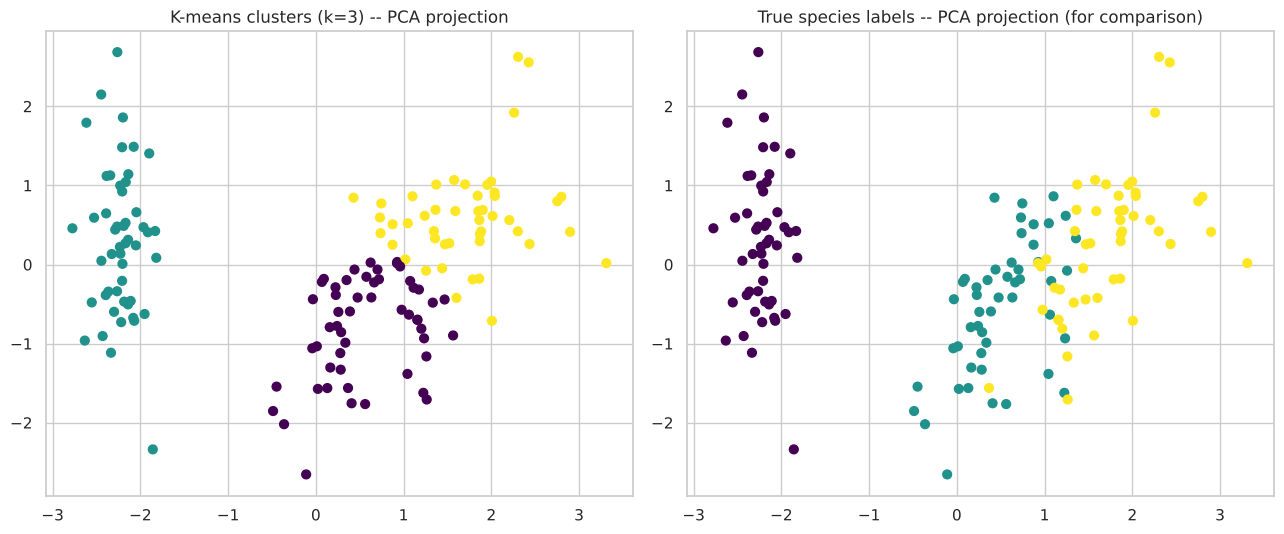

In [18]:
iris = load_iris()
X_iris = StandardScaler().fit_transform(iris.data)
y_iris_true = iris.target

km_iris = KMeans(n_clusters=3, random_state=2024, n_init=10)
y_iris_pred = km_iris.fit_predict(X_iris)

sil_iris = silhouette_score(X_iris, y_iris_pred)
ari_iris = adjusted_rand_score(y_iris_true, y_iris_pred)
print(f"Silhouette score: {sil_iris:.4f}")
print(f"ARI vs. true species labels (not used for fitting, only for checking): {ari_iris:.4f}")

pca_iris = PCA(n_components=2, random_state=2024)
X_iris_pca = pca_iris.fit_transform(X_iris)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
axes[0].scatter(X_iris_pca[:, 0], X_iris_pca[:, 1], c=y_iris_pred, cmap='viridis', s=40)
axes[0].set_title(f"K-means clusters (k=3) -- PCA projection")
axes[1].scatter(X_iris_pca[:, 0], X_iris_pca[:, 1], c=y_iris_true, cmap='viridis', s=40)
axes[1].set_title("True species labels -- PCA projection (for comparison)")
plt.tight_layout()
plt.show()

An ARI well above 0 (and typically well above 0.5) confirms K-means largely rediscovers the three true Iris species **without ever seeing the species labels** — strong evidence that the species really do form natural, geometrically separable clusters in feature space, which is exactly why Iris is such a popular toy dataset for both supervised and unsupervised demonstrations alike.

### Exercise 2: DBSCAN vs. K-means on moon data

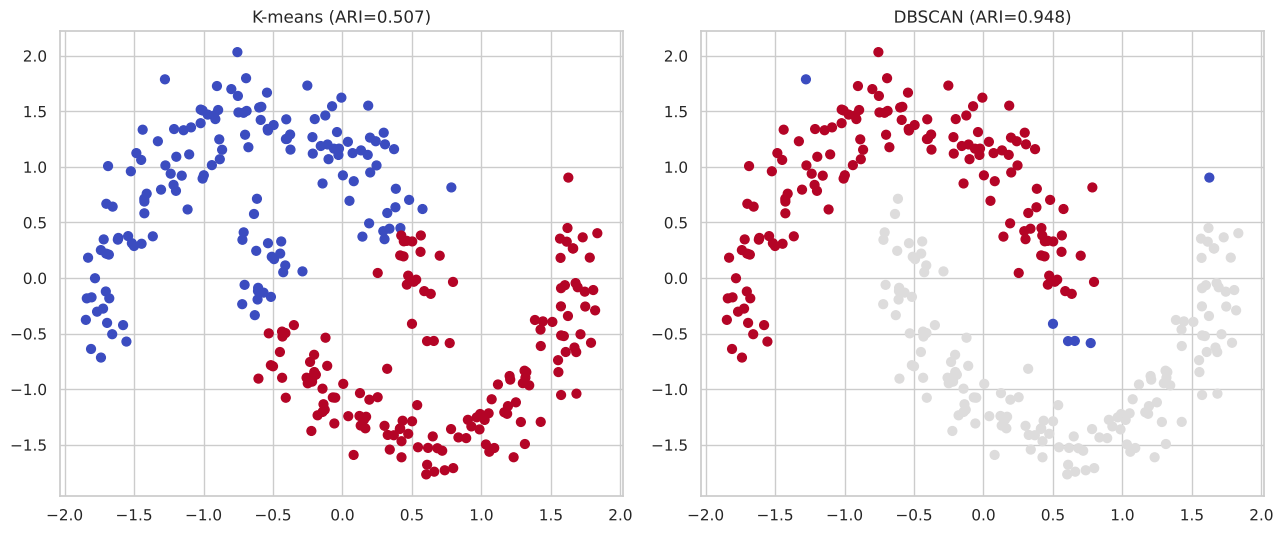

K-means ARI: 0.5072
DBSCAN ARI:  0.9477


In [19]:
X_ex2, y_ex2_true = make_moons(n_samples=300, noise=0.1, random_state=2024)
X_ex2 = StandardScaler().fit_transform(X_ex2)

km_ex2 = KMeans(n_clusters=2, random_state=2024, n_init=10).fit_predict(X_ex2)
db_ex2 = DBSCAN(eps=0.3, min_samples=5).fit_predict(X_ex2)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
axes[0].scatter(X_ex2[:, 0], X_ex2[:, 1], c=km_ex2, cmap='coolwarm', s=40)
axes[0].set_title(f"K-means (ARI={adjusted_rand_score(y_ex2_true, km_ex2):.3f})")
axes[1].scatter(X_ex2[:, 0], X_ex2[:, 1], c=db_ex2, cmap='coolwarm', s=40)
axes[1].set_title(f"DBSCAN (ARI={adjusted_rand_score(y_ex2_true, db_ex2):.3f})")
plt.tight_layout()
plt.show()

print(f"K-means ARI: {adjusted_rand_score(y_ex2_true, km_ex2):.4f}")
print(f"DBSCAN ARI:  {adjusted_rand_score(y_ex2_true, db_ex2):.4f}")

### Exercise 3: Clustering high-dimensional data with PCA and GMM

PCA explained variance (2 components): 12.5% of 50 original features
GMM (fit on 2-D PCA projection) ARI vs. true classes: 0.1530


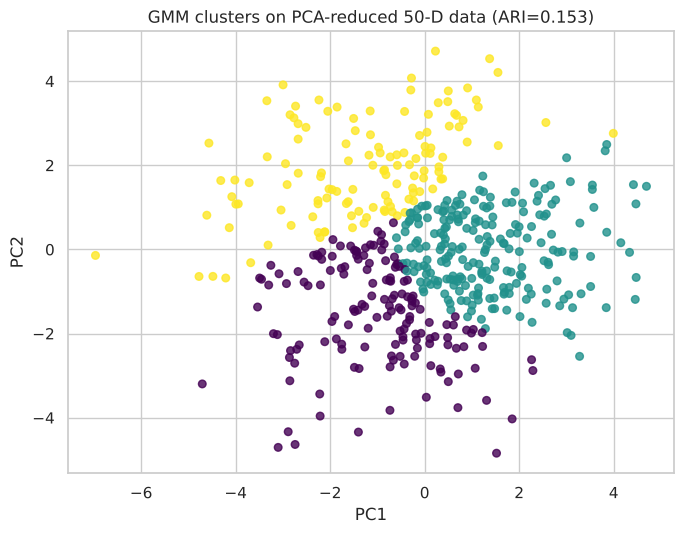

In [20]:
from sklearn.datasets import make_classification

X_hd, y_hd_true = make_classification(n_samples=500, n_features=50, n_informative=10, n_redundant=5,
                                       n_classes=3, n_clusters_per_class=1, random_state=2024)
X_hd = StandardScaler().fit_transform(X_hd)

pca_hd = PCA(n_components=2, random_state=2024)
X_hd_pca = pca_hd.fit_transform(X_hd)

gmm_hd = GaussianMixture(n_components=3, random_state=2024)
y_hd_pred = gmm_hd.fit_predict(X_hd_pca)  # fit GMM on the 2-D PCA projection

ari_hd = adjusted_rand_score(y_hd_true, y_hd_pred)
print(f"PCA explained variance (2 components): {pca_hd.explained_variance_ratio_.sum()*100:.1f}% "
      f"of {X_hd.shape[1]} original features")
print(f"GMM (fit on 2-D PCA projection) ARI vs. true classes: {ari_hd:.4f}")

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(X_hd_pca[:, 0], X_hd_pca[:, 1], c=y_hd_pred, cmap='viridis', s=30, alpha=0.8)
ax.set_title(f"GMM clusters on PCA-reduced 50-D data (ARI={ari_hd:.3f})")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
plt.tight_layout()
plt.show()

This exercise chains two unsupervised techniques together: PCA compresses 50 noisy features down to the 2 directions of greatest variance (Chapter 3), and GMM then clusters in that reduced, more tractable space — a common and practical pattern for clustering real-world high-dimensional data, where clustering directly in the original high-dimensional space is both computationally expensive and often less effective due to the curse of dimensionality.

## Summary

- **Clustering** is unsupervised: no target variable, only the goal of discovering structure in unlabeled data.
- **K-means** iterates assign→update to minimise inertia; works best on roughly spherical, similarly-sized, convex clusters; the elbow method (or silhouette score) helps choose $k$.
- **Hierarchical/agglomerative clustering** builds a full merge tree (dendrogram) bottom-up, letting $k$ be chosen after the fact by cutting the tree at a chosen height; the linkage method (`ward`, `complete`, `average`, `single`) changes the resulting tree shape.
- **DBSCAN** clusters by density, naturally handling non-convex shapes and explicitly flagging noise — verified directly against K-means' failure on moon-shaped data.
- **Evaluation without ground truth** uses internal metrics (silhouette, Davies-Bouldin, Calinski-Harabasz); a $k$-sweep showed these internal metrics did **not** all converge on the true $k=4$ in this run (silhouette and Davies-Bouldin preferred $k=2$, Calinski-Harabasz preferred $k=3$) — a concrete, honest demonstration that no single internal metric should be trusted blindly, which is itself the real lesson of evaluating clustering without ground truth.
- **Algorithm choice** should follow data shape: K-means/hierarchical for convex clusters, DBSCAN/spectral clustering for non-convex shapes and noisy data — demonstrated with a direct silhouette-score comparison across three synthetic shapes.
- **Advanced methods**: spectral clustering handles curved boundaries via graph-eigenspace methods; GMM offers soft, probabilistic cluster assignment well-suited to elliptical (not necessarily curved) cluster shapes.
- **Practical pattern**: PCA + clustering is a common combination for high-dimensional real-world data, trading some information loss for a clustering problem that is both faster and less afflicted by the curse of dimensionality.

This completes Chapter 10. In **Chapter 11**, we turn from "where are the groups?" to "which points don't belong to any group at all?" — **novelty and outlier detection**.